11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

==================== EDA: mnist ====================
Train: (60000, 28, 28) (60000,)
Test : (10000, 28, 28) (10000,)
Dtype: uint8 | Pixel range: 0 - 255
Mean: 33.32 | Std: 78.57


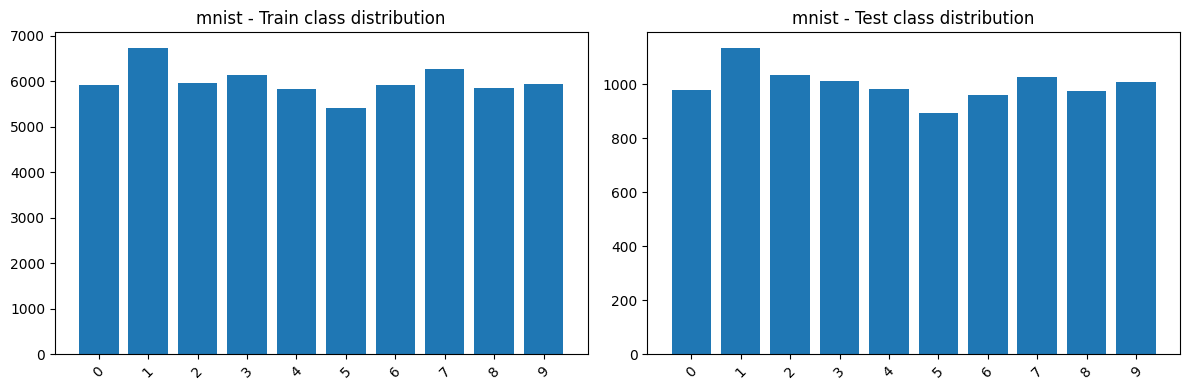

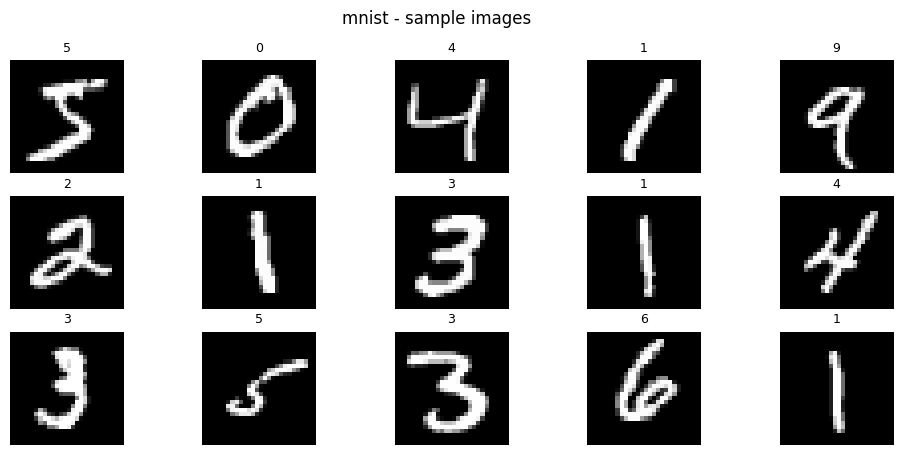

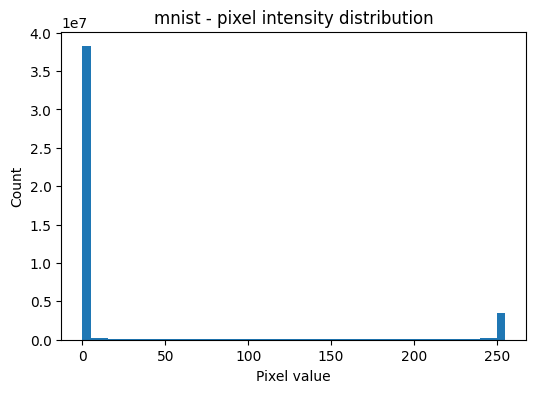

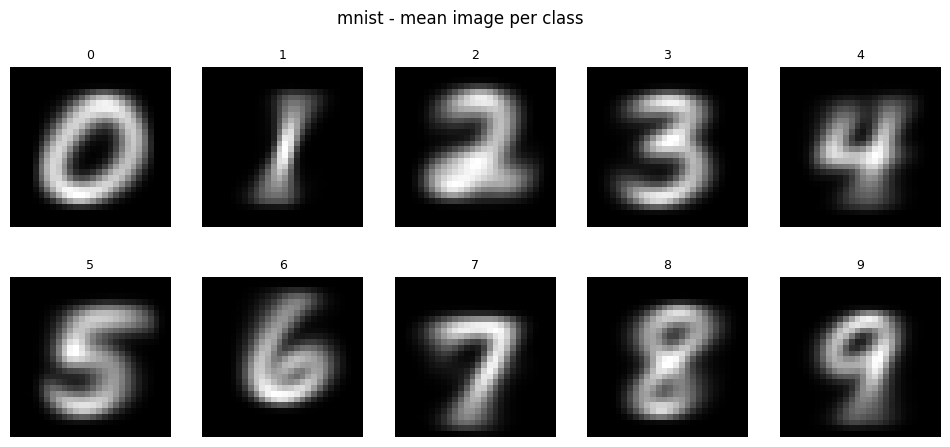

mnist train: saved 60000 PNG images
mnist test: saved 10000 PNG images
29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

==================== EDA: fashion_mnist ====================
Train: (60000, 28, 28) (60000,)
Test : (10000, 28, 28) (10000,)
Dtype: uint8 | Pixel range: 0 - 255
Mean: 72.94 | Std: 90.02


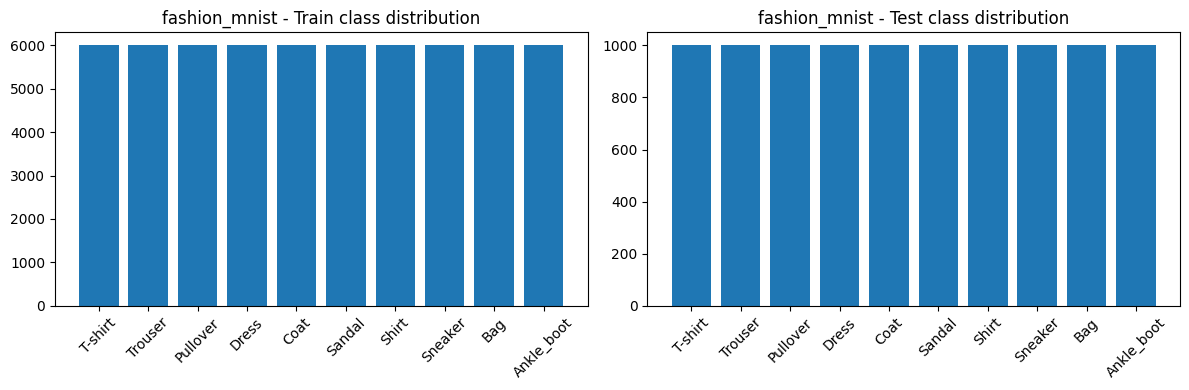

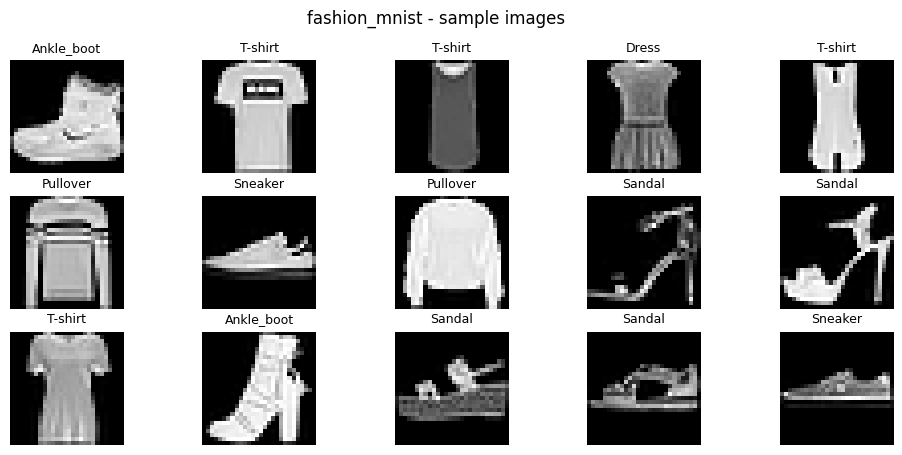

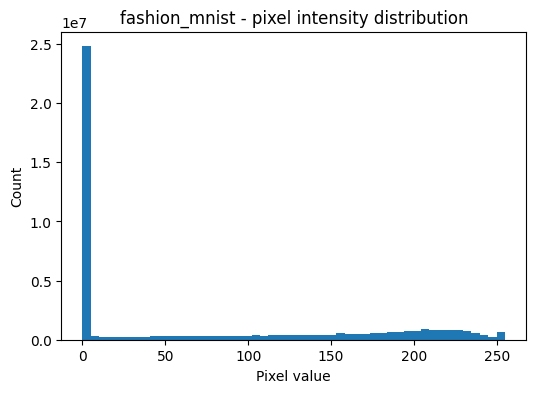

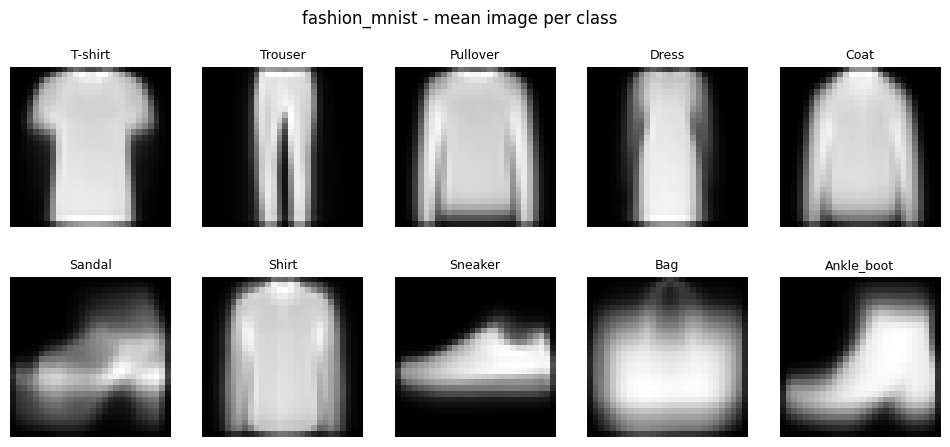

fashion_mnist train: saved 60000 PNG images
fashion_mnist test: saved 10000 PNG images
170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 36s 0us/step

==================== EDA: cifar10 ====================
Train: (50000, 32, 32, 3) (50000,)
Test : (10000, 32, 32, 3) (10000,)
Dtype: uint8 | Pixel range: 0 - 255
Mean: 120.71 | Std: 64.15
  R mean: 125.31, std: 62.99
  G mean: 122.95, std: 62.09
  B mean: 113.87, std: 66.70


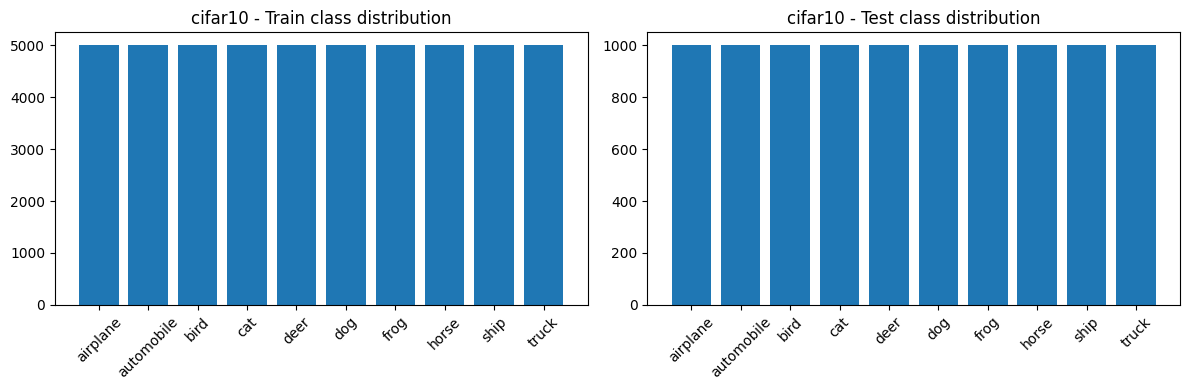

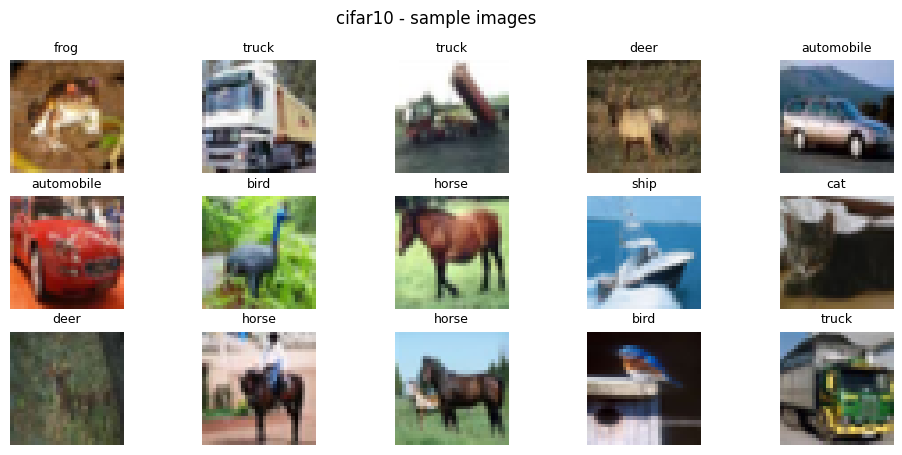

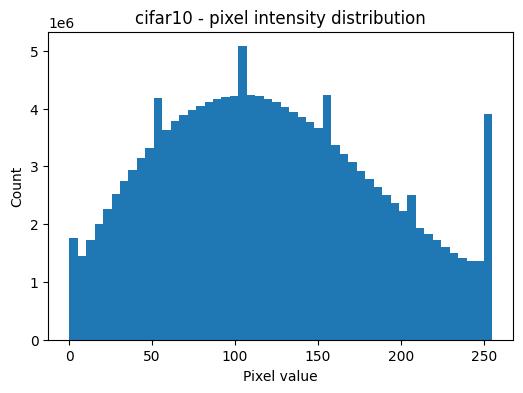

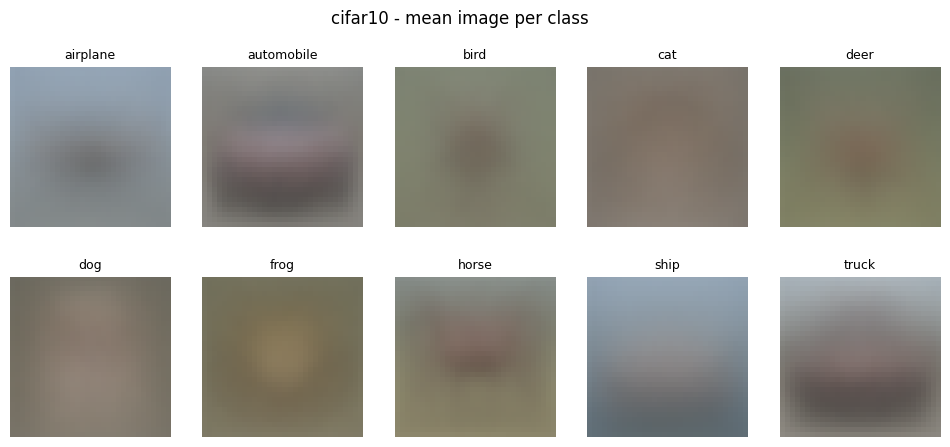

cifar10 train: saved 50000 PNG images
cifar10 test: saved 10000 PNG images

Done. Folders: ['cifar10', 'fashion_mnist', 'mnist']


In [1]:
import os, pickle, tarfile, urllib.request
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tensorflow.keras.datasets import mnist, fashion_mnist, cifar10

# ================= SETTINGS =================
RUN_EDA      = True    # plots + statistics
SAVE_PNG     = True    # export images as PNG files
ZIP_DOWNLOAD = False   # zip and download the PNG folder
LIMIT        = None    # e.g. 1000 for a quick test; None = save all images
OUT          = "all_datasets_png"

# ================= DATASET INFO =================
datasets = {
    "mnist": (mnist, [str(i) for i in range(10)]),
    "fashion_mnist": (fashion_mnist, ["T-shirt", "Trouser", "Pullover", "Dress", "Coat",
                                      "Sandal", "Shirt", "Sneaker", "Bag", "Ankle_boot"]),
    "cifar10": (cifar10, ["airplane", "automobile", "bird", "cat", "deer",
                          "dog", "frog", "horse", "ship", "truck"]),
}

# ================= CIFAR-10 MANUAL FALLBACK =================
def load_cifar10_manual():
    folder = "cifar-10-batches-py"
    if not os.path.exists(folder):
        print("Downloading CIFAR-10 manually (~163 MB)...")
        urllib.request.urlretrieve(
            "https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz", "cifar.tar.gz")
        with tarfile.open("cifar.tar.gz") as t:
            t.extractall()

    def load_batch(name):
        with open(f"{folder}/{name}", "rb") as f:
            d = pickle.load(f, encoding="bytes")
        return d[b"data"].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1), np.array(d[b"labels"])

    parts = [load_batch(f"data_batch_{i}") for i in range(1, 6)]
    x_tr = np.concatenate([p[0] for p in parts])
    y_tr = np.concatenate([p[1] for p in parts])
    x_te, y_te = load_batch("test_batch")
    return (x_tr, y_tr), (x_te, y_te)

def load_data(name, loader):
    try:
        (xtr, ytr), (xte, yte) = loader.load_data()
    except Exception as e:
        if name != "cifar10":
            raise
        print("Keras load failed for CIFAR-10:", e)
        (xtr, ytr), (xte, yte) = load_cifar10_manual()
    return (xtr, np.array(ytr).flatten()), (xte, np.array(yte).flatten())

# ================= EDA =================
def run_eda(name, x_train, y_train, x_test, y_test, classes):
    is_color = x_train.ndim == 4
    cmap = None if is_color else "gray"
    print(f"\n{'='*20} EDA: {name} {'='*20}")
    print("Train:", x_train.shape, y_train.shape)
    print("Test :", x_test.shape, y_test.shape)
    print("Dtype:", x_train.dtype, "| Pixel range:", x_train.min(), "-", x_train.max())
    print("Mean: %.2f | Std: %.2f" % (x_train.mean(), x_train.std()))
    if is_color:
        for i, ch in enumerate("RGB"):
            print(f"  {ch} mean: {x_train[..., i].mean():.2f}, std: {x_train[..., i].std():.2f}")

    # Class distribution
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for a, y, t in zip(ax, [y_train, y_test], ["Train", "Test"]):
        a.bar(classes, np.bincount(y))
        a.set_title(f"{name} - {t} class distribution")
        a.tick_params(axis="x", rotation=45)
    plt.tight_layout(); plt.show()

    # Sample images
    plt.figure(figsize=(12, 5))
    for i in range(15):
        plt.subplot(3, 5, i + 1)
        plt.imshow(x_train[i], cmap=cmap)
        plt.title(classes[y_train[i]], fontsize=9)
        plt.axis("off")
    plt.suptitle(f"{name} - sample images"); plt.show()

    # Pixel intensity histogram
    plt.figure(figsize=(6, 4))
    plt.hist(x_train.ravel(), bins=50)
    plt.title(f"{name} - pixel intensity distribution")
    plt.xlabel("Pixel value"); plt.ylabel("Count"); plt.show()

    # Mean image per class
    plt.figure(figsize=(12, 5))
    for c in range(10):
        m = x_train[y_train == c].mean(axis=0)
        if is_color:
            m = m / 255.0
        plt.subplot(2, 5, c + 1)
        plt.imshow(m, cmap=cmap)
        plt.title(classes[c], fontsize=9)
        plt.axis("off")
    plt.suptitle(f"{name} - mean image per class"); plt.show()

# ================= SAVE PNG =================
def save_split(x, y, name, split, classes):
    n = len(x) if LIMIT is None else min(LIMIT, len(x))
    for c in classes:
        os.makedirs(f"{OUT}/{name}/{split}/{c}", exist_ok=True)
    for i in range(n):
        Image.fromarray(x[i]).save(f"{OUT}/{name}/{split}/{classes[y[i]]}/{i}.png")
    print(f"{name} {split}: saved {n} PNG images")

# ================= MAIN =================
for name, (loader, classes) in datasets.items():
    (x_train, y_train), (x_test, y_test) = load_data(name, loader)
    if RUN_EDA:
        run_eda(name, x_train, y_train, x_test, y_test, classes)
    if SAVE_PNG:
        save_split(x_train, y_train, name, "train", classes)
        save_split(x_test, y_test, name, "test", classes)

if SAVE_PNG:
    print("\nDone. Folders:", os.listdir(OUT))

if SAVE_PNG and ZIP_DOWNLOAD:
    os.system(f"zip -rq {OUT}.zip {OUT}")
    from google.colab import files
    files.download(f"{OUT}.zip")